# MNIST Experiments

### Imports

In [1]:
import pickle

from os.path import exists, isdir, join as path_join
from os import makedirs, listdir

In [2]:
from torchvision import datasets, transforms, utils
import torch
import numpy as np

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import os
import re

### Load Datasets

- Visualize digits
- Visualize inbalance

In [4]:
emnist_root = 'datasets/emnist'
emnist_split = 'mnist'
exps_root = f"clustering_{emnist_split}"
k=10

In [5]:
clustered_train_dataset_path = path_join(exps_root, f"train_{emnist_split}_{k}_dataset.pkl")
clustered_test_dataset_path = path_join(exps_root, f"test_{emnist_split}_{k}_dataset.pkl")

assert exists(clustered_train_dataset_path) and exists(clustered_test_dataset_path), "Missing dataset files!"

with open(clustered_train_dataset_path, 'rb') as f:
    clustered_train_dataset = pickle.load(f)

with open(clustered_test_dataset_path, 'rb') as f:
    clustered_test_dataset = pickle.load(f)

In [6]:
assert hasattr(clustered_train_dataset, 'idx_col'), "Corrupted clustered train dataset"
assert hasattr(clustered_test_dataset, 'idx_col'), "Corrupted clustered test dataset"

In [7]:
transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),  # ResNet expects 3 channels
    transforms.Resize((32, 32)),  # Resize to 32x32 as ResNet typically expects this size
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

test_dataset = datasets.EMNIST(
    root=emnist_root,
    split=emnist_split,  # Use the same split as for the train dataset
    train=False,
    transform=transform,
)

### Results

- Mention training scripts

- Plots

In [8]:
clustered_train_dataset[0]

(tensor([[[-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.],
          ...,
          [-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.]],
 
         [[-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.],
          ...,
          [-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.]],
 
         [[-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.],
          ...,
          [-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.]]]),
 5,
 3)

In [9]:
clustered_test_dataset[0]

(tensor([[[-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.],
          ...,
          [-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.]],
 
         [[-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.],
          ...,
          [-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.]],
 
         [[-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.],
          ...,
          [-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.]]]),
 7,
 1)

In [10]:
clustered_test_dataset[0][0].min(), clustered_test_dataset[0][0].max()

(tensor(-1.), tensor(1.))

In [11]:
train_class_cluster = dict()
train_class_cluster_avg_img = dict() 
train_class_cluster_avg_count = dict() 

for img, target, cluster in clustered_train_dataset:
    train_class_cluster[target] = train_class_cluster.get(target, set())
    train_class_cluster[target].add(cluster)
    train_class_cluster_avg_img[target, cluster] = train_class_cluster_avg_img.get((target, cluster), torch.zeros(img.shape)) + img
    train_class_cluster_avg_count[target, cluster] = train_class_cluster_avg_count.get((target, cluster), 0) +1
    
for key, value in train_class_cluster_avg_img.items():
    train_class_cluster_avg_img[key] = value / train_class_cluster_avg_count[key]

In [14]:
train_class_cluster_avg_count

{(5, 3): 1005,
 (3, 2): 631,
 (0, 2): 773,
 (6, 1): 907,
 (9, 1): 1005,
 (7, 0): 1107,
 (8, 1): 609,
 (2, 3): 897,
 (1, 2): 1020,
 (4, 0): 666}

In [15]:
test_class_cluster = dict()
test_class_cluster_avg_img = dict() 
test_class_cluster_avg_count = dict() 

for img, target, cluster in clustered_test_dataset:
    test_class_cluster[target] = test_class_cluster.get(target, set())
    test_class_cluster[target].add(cluster)
    test_class_cluster_avg_img[target, cluster] = test_class_cluster_avg_img.get((target, cluster), torch.zeros(img.shape)) + img
    test_class_cluster_avg_count[target, cluster] = test_class_cluster_avg_count.get((target, cluster), 0 ) + 1

for key, value in test_class_cluster_avg_img.items():
    test_class_cluster_avg_img[key] = value / test_class_cluster_avg_count[key]
    

In [16]:
key = next(iter(train_class_cluster_avg_img.keys()))
train_class_cluster_avg_img[key]

tensor([[[-1.0000, -1.0000, -1.0000,  ..., -1.0000, -1.0000, -1.0000],
         [-1.0000, -1.0000, -1.0000,  ..., -1.0000, -1.0000, -1.0000],
         [-1.0000, -1.0000, -1.0000,  ..., -0.9990, -1.0000, -1.0000],
         ...,
         [-1.0000, -0.9998, -0.9898,  ..., -1.0000, -1.0000, -1.0000],
         [-1.0000, -1.0000, -0.9998,  ..., -1.0000, -1.0000, -1.0000],
         [-1.0000, -1.0000, -1.0000,  ..., -1.0000, -1.0000, -1.0000]],

        [[-1.0000, -1.0000, -1.0000,  ..., -1.0000, -1.0000, -1.0000],
         [-1.0000, -1.0000, -1.0000,  ..., -1.0000, -1.0000, -1.0000],
         [-1.0000, -1.0000, -1.0000,  ..., -0.9990, -1.0000, -1.0000],
         ...,
         [-1.0000, -0.9998, -0.9898,  ..., -1.0000, -1.0000, -1.0000],
         [-1.0000, -1.0000, -0.9998,  ..., -1.0000, -1.0000, -1.0000],
         [-1.0000, -1.0000, -1.0000,  ..., -1.0000, -1.0000, -1.0000]],

        [[-1.0000, -1.0000, -1.0000,  ..., -1.0000, -1.0000, -1.0000],
         [-1.0000, -1.0000, -1.0000,  ..., -1

In [17]:
train_class_cluster_avg_img[key]

tensor([[[-1.0000, -1.0000, -1.0000,  ..., -1.0000, -1.0000, -1.0000],
         [-1.0000, -1.0000, -1.0000,  ..., -1.0000, -1.0000, -1.0000],
         [-1.0000, -1.0000, -1.0000,  ..., -0.9990, -1.0000, -1.0000],
         ...,
         [-1.0000, -0.9998, -0.9898,  ..., -1.0000, -1.0000, -1.0000],
         [-1.0000, -1.0000, -0.9998,  ..., -1.0000, -1.0000, -1.0000],
         [-1.0000, -1.0000, -1.0000,  ..., -1.0000, -1.0000, -1.0000]],

        [[-1.0000, -1.0000, -1.0000,  ..., -1.0000, -1.0000, -1.0000],
         [-1.0000, -1.0000, -1.0000,  ..., -1.0000, -1.0000, -1.0000],
         [-1.0000, -1.0000, -1.0000,  ..., -0.9990, -1.0000, -1.0000],
         ...,
         [-1.0000, -0.9998, -0.9898,  ..., -1.0000, -1.0000, -1.0000],
         [-1.0000, -1.0000, -0.9998,  ..., -1.0000, -1.0000, -1.0000],
         [-1.0000, -1.0000, -1.0000,  ..., -1.0000, -1.0000, -1.0000]],

        [[-1.0000, -1.0000, -1.0000,  ..., -1.0000, -1.0000, -1.0000],
         [-1.0000, -1.0000, -1.0000,  ..., -1

In [18]:
train_class_cluster

{5: {3},
 3: {2},
 0: {2},
 6: {1},
 9: {1},
 7: {0},
 8: {1},
 2: {3},
 1: {2},
 4: {0}}

In [19]:
test_class_cluster

{7: {1},
 8: {2},
 0: {8},
 3: {3},
 4: {4},
 2: {8},
 1: {8},
 5: {8},
 9: {6},
 6: {8}}

In [20]:
test_dataset[0]

(tensor([[[-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.],
          ...,
          [-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.]],
 
         [[-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.],
          ...,
          [-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.]],
 
         [[-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.],
          ...,
          [-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.]]]),
 1)

In [21]:
test_dataset[0][0].min(), test_dataset[0][0].max()

(tensor(-1.), tensor(1.))

### Ploting clustered train digits examples:

In [49]:
# Initialize a dictionary to store one example per digit
examples = {}
counts = dict()

# Iterate through the train dataset to collect one example for each digit
for image, label, _ in clustered_train_dataset:
    counts[label] = counts.get(label, 0) + 1
    if label not in examples:
        examples[label] = image
    # # Stop if all digits (0-9) are collected
    # if len(examples) == 10:
    #     break

print(counts)

{5: 1005, 3: 631, 0: 773, 6: 907, 9: 1005, 7: 1107, 8: 609, 2: 897, 1: 1020, 4: 666}


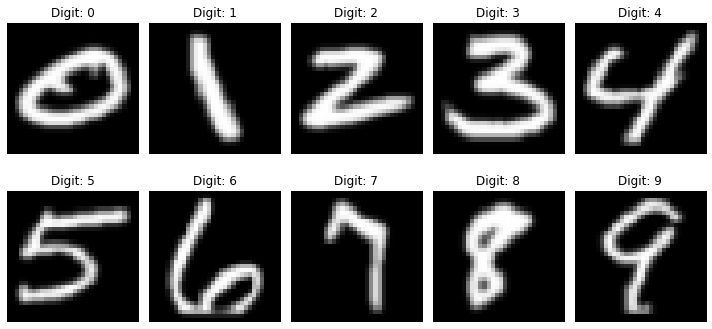

In [51]:
# Create a grid of plots for the digits
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
axes = axes.flatten()

for idx, (digit, img) in enumerate(sorted(examples.items())):
    axes[idx].imshow(img.permute(2, 1, 0).numpy() * 0.5 + 0.5)  # Unnormalize the image
    axes[idx].set_title(f"Digit: {digit}")
    axes[idx].axis("off")

fig.savefig("clustering_mnist/photo_clustered_train.pdf")
plt.tight_layout()
plt.show()

In [44]:
def compare_digits(digit, fig_path=None):
    fig, axes = plt.subplots(1,2, figsize=(10, 5))
    axes = axes.flatten()
    
    train_cluster = next(iter(train_class_cluster[digit]))
    test_cluster = next(iter(test_class_cluster[digit]))
    
    img = train_class_cluster_avg_img[digit, train_cluster]
    axes[0].imshow(img.permute(2, 1, 0).numpy() * 0.5 + 0.5)  # Unnormalize the image
    axes[0].set_title(f"Average of digit {digit} in the training set ")
    axes[0].axis("off")
    
    img = test_class_cluster_avg_img[digit, test_cluster]
    axes[1].imshow(img.permute(2, 1, 0).numpy() * 0.5 + 0.5)  # Unnormalize the image
    axes[1].set_title(f"Average of digit {digit} in the testing set ")
    axes[1].axis("off")
    
    plt.tight_layout()
    if fig_path is not None:
        fig.savefig(fig_path)
    plt.show()

# train_class_cluster
# for cluster in train_class_cluster[digit]:
#     img = train_class_cluster_avg_img[digit, cluster]
#     plt.imshow(img.permute(2, 1, 0).numpy() * 0.5 + 0.5)  # Unnormalize the image
#     plt.title(f"Average rerpresentation of digit {digit} in the training set ")
#     axes[idx].axis("off")



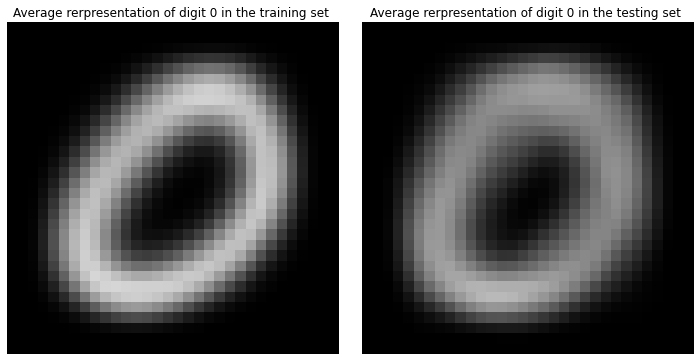

In [25]:
compare_digits(0)

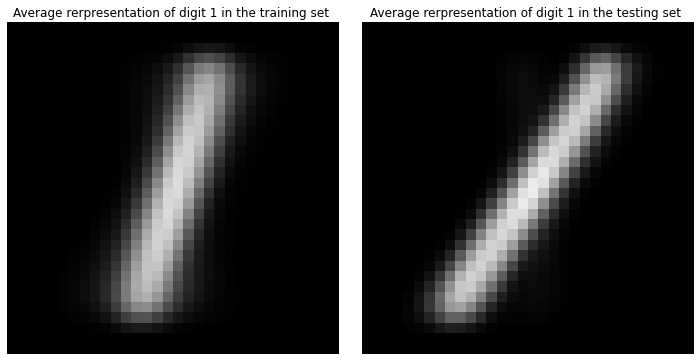

In [26]:
compare_digits(1)

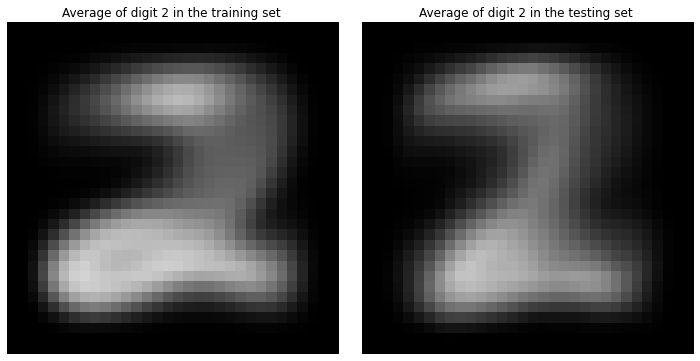

In [45]:
compare_digits(2, "clustering_mnist/pair_of_2.pdf")

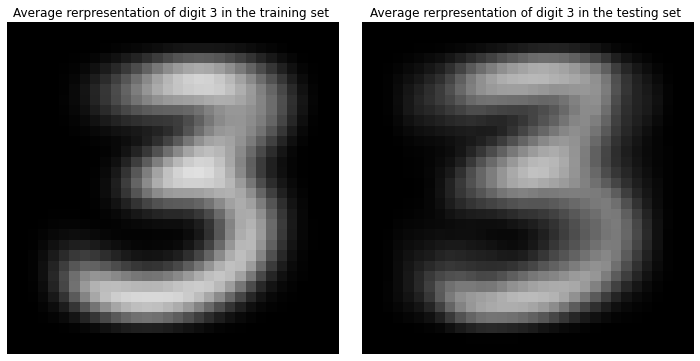

In [28]:
compare_digits(3)

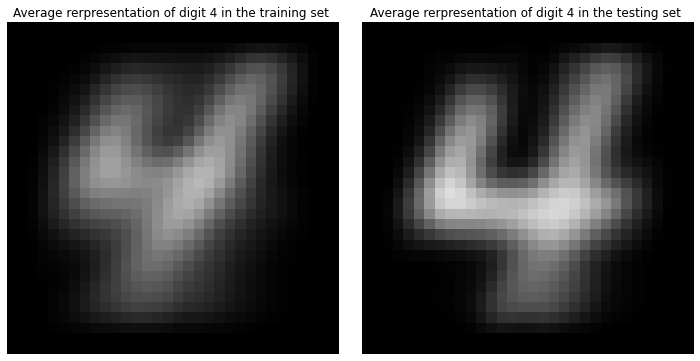

In [29]:
compare_digits(4)

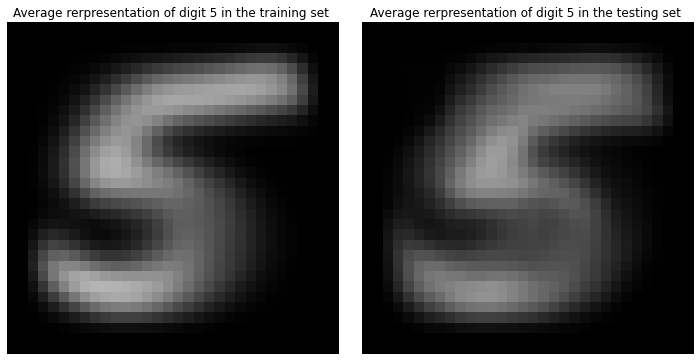

In [30]:
compare_digits(5)

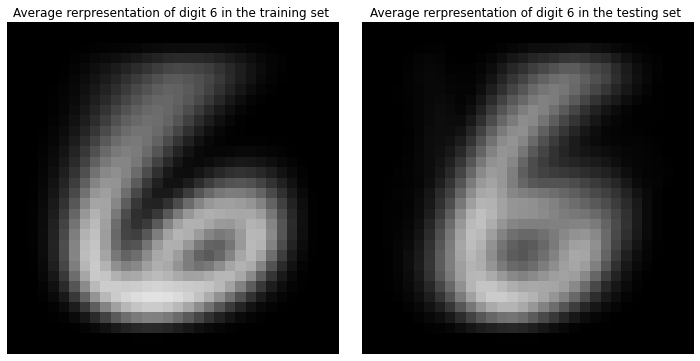

In [31]:
compare_digits(6)

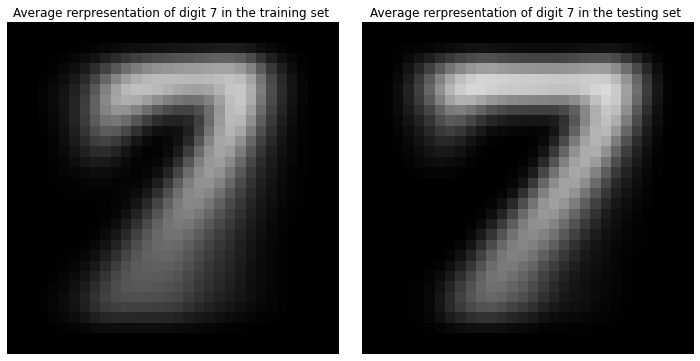

In [32]:
compare_digits(7)

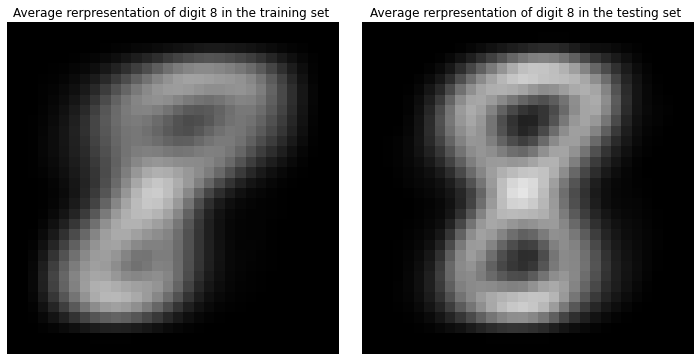

In [33]:
compare_digits(8)

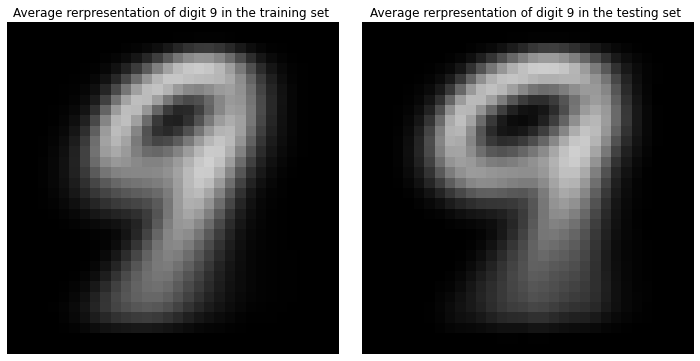

In [34]:
compare_digits(9)

In [ ]:
# digit = 4

# test_class_cluster
# for cluster in test_class_cluster[digit]:
#     img = test_class_cluster_avg_img[digit, cluster]
#     plt.imshow(img.permute(2, 1, 0).numpy() * 0.5 + 0.5)  # Unnormalize the image
#     plt.title(f"Average rerpresentation of digit {digit} in the test set ")
#     axes[idx].axis("off")

In [35]:
for digit in range(10):
    train_c = next(iter(train_class_cluster[digit]))
    test_c = next(iter(test_class_cluster[digit]))
    print( f"Distance between clusters of digit {digit} in the test and train sets {(test_class_cluster_avg_img[digit,test_c] - train_class_cluster_avg_img[digit,train_c]).pow(2).sum().sqrt()}")


Distance between clusters of digit 0 in the test and train sets 10.39474868774414
Distance between clusters of digit 1 in the test and train sets 17.534984588623047
Distance between clusters of digit 2 in the test and train sets 12.109630584716797
Distance between clusters of digit 3 in the test and train sets 9.649964332580566
Distance between clusters of digit 4 in the test and train sets 12.282232284545898
Distance between clusters of digit 5 in the test and train sets 8.108505249023438
Distance between clusters of digit 6 in the test and train sets 15.518159866333008
Distance between clusters of digit 7 in the test and train sets 9.039753913879395
Distance between clusters of digit 8 in the test and train sets 16.529644012451172
Distance between clusters of digit 9 in the test and train sets 10.42087459564209


### Ploting clustered test digits examples:

In [46]:
# Initialize a dictionary to store one example per digit
examples = {}

counts = dict()

# Iterate through the test dataset to collect one example for each digit
for image, label, _ in clustered_test_dataset:
    counts[label] = counts.get(label, 0) + 1
    if label not in examples:
        examples[label] = image
    # # Stop if all digits (0-9) are collected
    # if len(examples) == 10:
    #     break

print(counts)


{7: 171, 8: 127, 0: 141, 3: 108, 4: 132, 2: 144, 1: 122, 5: 105, 9: 199, 6: 90}


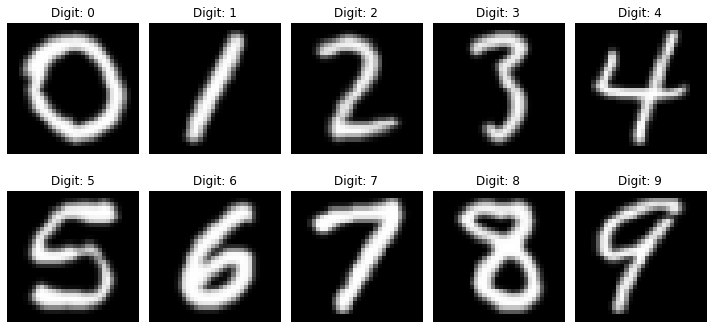

In [48]:
# Create a grid of plots for the digits
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
axes = axes.flatten()

for idx, (digit, img) in enumerate(sorted(examples.items())):
    axes[idx].imshow(img.permute(2, 1, 0).numpy() * 0.5 + 0.5)  # Unnormalize the image
    axes[idx].set_title(f"Digit: {digit}")
    axes[idx].axis("off")

fig.savefig("clustering_mnist/photo_clustered_test.pdf")
plt.tight_layout()
plt.show()

### Ploting test digits examples:

In [38]:
# Initialize a dictionary to store one example per digit
examples = {}

# Iterate through the test dataset to collect one example for each digit
for image, label in test_dataset:
    if label not in examples:
        examples[label] = image
    # Stop if all digits (0-9) are collected
    if len(examples) == 10:
        break



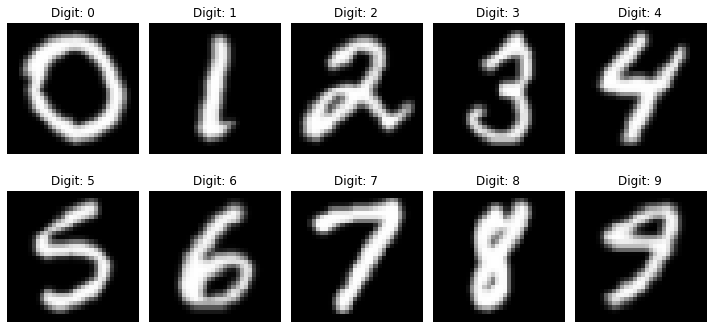

In [39]:
# Create a grid of plots for the digits
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
axes = axes.flatten()

for idx, (digit, img) in enumerate(sorted(examples.items())):
    axes[idx].imshow(img.permute(2, 1, 0).numpy() * 0.5 + 0.5)  # Unnormalize the image
    axes[idx].set_title(f"Digit: {digit}")
    axes[idx].axis("off")

plt.tight_layout()
plt.show()

In [40]:
len(clustered_train_dataset.idx_col)

8620

In [52]:
clustered_train_dataset.idx_col

(16,
 24,
 29,
 36,
 43,
 57,
 77,
 78,
 90,
 93,
 111,
 120,
 127,
 129,
 132,
 135,
 151,
 154,
 157,
 168,
 169,
 170,
 187,
 190,
 192,
 195,
 199,
 216,
 223,
 224,
 225,
 244,
 252,
 262,
 268,
 279,
 281,
 285,
 294,
 299,
 302,
 322,
 323,
 336,
 339,
 354,
 372,
 380,
 395,
 397,
 403,
 410,
 425,
 437,
 448,
 450,
 453,
 468,
 470,
 483,
 489,
 497,
 499,
 502,
 522,
 529,
 530,
 534,
 536,
 538,
 544,
 548,
 551,
 563,
 564,
 565,
 590,
 591,
 594,
 598,
 599,
 601,
 602,
 604,
 610,
 614,
 616,
 622,
 628,
 636,
 638,
 643,
 648,
 653,
 659,
 665,
 671,
 678,
 681,
 682,
 688,
 694,
 699,
 701,
 704,
 706,
 709,
 710,
 714,
 719,
 721,
 739,
 770,
 771,
 777,
 780,
 783,
 793,
 807,
 816,
 823,
 828,
 829,
 841,
 845,
 855,
 869,
 873,
 881,
 882,
 883,
 886,
 887,
 892,
 893,
 898,
 901,
 907,
 924,
 938,
 947,
 950,
 959,
 966,
 968,
 980,
 985,
 989,
 1002,
 1007,
 1014,
 1015,
 1016,
 1019,
 1025,
 1042,
 1053,
 1056,
 1066,
 1079,
 1093,
 1107,
 1116,
 1118,
 1119,
 11

### Experiments

#### Clustered Training and Clustered testing

#### Clustered Training and full testing

#### Full Training and full testing : baseline
Although it is possible to cause grokking in this setting, we show that with the same set of hiperparameters, there is no grokking when the data distribution matches.

In [53]:
def get_all_csv(root_folder = 'experiments', regex=r".*frac\[(\d+(?:\.\d+)?)\].*", verbose=False):
    # Loop through all folders in the root folder
    dataframes = []
    for entry in listdir(root_folder):
        folder = path_join(root_folder, entry)
        match = re.search(regex, entry)
        if match and isdir(folder):
            # Check if the folder contains CSV files
            csv_files = [f for f in os.listdir(folder) if f.endswith('.csv')]
            if(verbose):
                if match.groupdict():
                    print(f"Folder {entry}, {str(match.groupdict())[1:-1]}")
                else:
                    print(f"Folder {entry}, {str(match.groups())[1:-1]}")
            
            # Loop through each CSV file in the folder
            for csv_file in csv_files:
                # Read the CSV file into a pandas dataframe
                dataframe = pd.read_csv(os.path.join(folder, csv_file))
                dataframes.append(dataframe)
    return pd.concat(dataframes) if len(dataframes) > 0 else None

In [54]:
root_folder="experiments"
for entry in listdir(root_folder, ):
    folder = path_join(root_folder, entry)
    if isdir(folder):
        break

In [55]:
exp_regex = r"mnist(?P<date>\d\d\d\d-\d\d-\d\d-\d\d-\d\d-\d\d)(?P<split>\w*)_\[\d*.\d*\]frac"
exp_regex_mnist_10 = r"mnist(?P<date>\d\d\d\d-\d\d-\d\d-\d\d-\d\d-\d\d)(?P<split>mnist_10)_\[\d*.\d*\]frac"
exp_regex_mnist_10_all = r"mnist(?P<date>\d\d\d\d-\d\d-\d\d-\d\d-\d\d-\d\d)(?P<split>mnist_10_all)_\[\d*.\d*\]frac"
exp_regex_mnist_all = r"mnist(?P<date>\d\d\d\d-\d\d-\d\d-\d\d-\d\d-\d\d)(?P<split>mnist_all)_\[\d*.\d*\]frac"

In [56]:
df_10 = get_all_csv(root_folder='experiments', regex=exp_regex_mnist_10, verbose=True)

Folder mnist2025-01-26-18-00-57mnist_10_[1.0]frac, 'date': '2025-01-26-18-00-57', 'split': 'mnist_10'
Folder mnist2025-01-27-13-58-22mnist_10_[1.0]frac, 'date': '2025-01-27-13-58-22', 'split': 'mnist_10'
Folder mnist2025-01-27-13-58-27mnist_10_[1.0]frac, 'date': '2025-01-27-13-58-27', 'split': 'mnist_10'
Folder mnist2025-01-27-13-58-07mnist_10_[1.0]frac, 'date': '2025-01-27-13-58-07', 'split': 'mnist_10'
Folder mnist2025-01-27-13-58-06mnist_10_[1.0]frac, 'date': '2025-01-27-13-58-06', 'split': 'mnist_10'
Folder mnist2025-01-27-13-58-09mnist_10_[1.0]frac, 'date': '2025-01-27-13-58-09', 'split': 'mnist_10'
Folder mnist2025-01-26-18-08-20mnist_10_[1.0]frac, 'date': '2025-01-26-18-08-20', 'split': 'mnist_10'
Folder mnist2025-01-26-19-03-29mnist_10_[1.0]frac, 'date': '2025-01-26-19-03-29', 'split': 'mnist_10'
Folder mnist2025-01-27-13-58-08mnist_10_[1.0]frac, 'date': '2025-01-27-13-58-08', 'split': 'mnist_10'


In [57]:
df_10.columns

Index(['Unnamed: 0', 'lr', 'weight_decay', 'scaling_factor', 'num_samples',
       'optimization_steps', 'step', 'test_accuracy', 'train_accuracy',
       'train_loss', 'weight_norm'],
      dtype='object')

In [58]:
def plot_accuracy(data, img_path = None, row=None, col=None, yaxis = (0.5, 1.0),bbox_to_anchor=(0.5, 1.1), alpha=1.0):
    # Set up the FacetGrid
    if data is None:
        return None
    g = sns.FacetGrid(data, row=row, col=col, margin_titles=True)
    
    # Map the plotting function to each subset of the data with alpha values
    g.map(sns.lineplot, 'step', 'test_accuracy', color='blue', alpha=alpha, label='Test Accuracy')
    g.map(sns.lineplot, 'step', 'train_accuracy', color='orange', alpha=alpha, label='Train Accuracy')

    if yaxis is not None:
        # Set the y-axis limits for all subplots
        g.set(ylim=yaxis)
    
    # Add legend
    handles, labels = g.axes[0, 0].get_legend_handles_labels()  # Get legend from any axis
    lgd = g.fig.legend(handles, labels, loc='upper center', bbox_to_anchor=bbox_to_anchor, ncol=2)
    
    # Adjust layout
    plt.tight_layout()
    fig = plt.gcf()
    if(img_path is not None):
        fig.savefig(img_path, bbox_extra_artists=(lgd,), bbox_inches='tight')
    plt.show()
    return fig

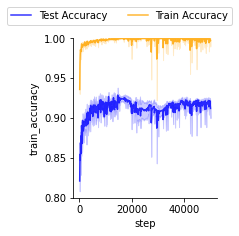

In [59]:
fig = plot_accuracy(df_10, img_path = None, yaxis = (0.8, 1.0), alpha=0.8)

In [60]:
df_10_all = get_all_csv(root_folder='experiments', regex=exp_regex_mnist_10_all, verbose=True)

Folder mnist2025-01-30-09-39-55mnist_10_all_[1.0]frac, 'date': '2025-01-30-09-39-55', 'split': 'mnist_10_all'
Folder mnist2025-01-30-09-29-01mnist_10_all_[1.0]frac, 'date': '2025-01-30-09-29-01', 'split': 'mnist_10_all'
Folder mnist2025-01-30-09-51-36mnist_10_all_[1.0]frac, 'date': '2025-01-30-09-51-36', 'split': 'mnist_10_all'
Folder mnist2025-01-30-09-45-03mnist_10_all_[1.0]frac, 'date': '2025-01-30-09-45-03', 'split': 'mnist_10_all'
Folder mnist2025-01-29-13-30-27mnist_10_all_[1.0]frac, 'date': '2025-01-29-13-30-27', 'split': 'mnist_10_all'
Folder mnist2025-01-30-09-30-39mnist_10_all_[1.0]frac, 'date': '2025-01-30-09-30-39', 'split': 'mnist_10_all'
Folder mnist2025-01-30-09-41-05mnist_10_all_[1.0]frac, 'date': '2025-01-30-09-41-05', 'split': 'mnist_10_all'
Folder mnist2025-01-30-09-30-09mnist_10_all_[1.0]frac, 'date': '2025-01-30-09-30-09', 'split': 'mnist_10_all'
Folder mnist2025-01-30-09-39-42mnist_10_all_[1.0]frac, 'date': '2025-01-30-09-39-42', 'split': 'mnist_10_all'
Folder mni

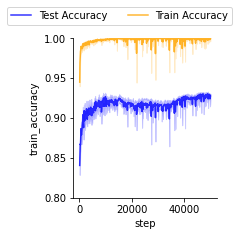

In [61]:
fig = plot_accuracy(df_10_all, img_path = None, yaxis = (0.8, 1.0), alpha=0.8)

In [62]:
df_all = get_all_csv(root_folder='experiments', regex=exp_regex_mnist_all, verbose=True)

Folder mnist2025-01-30-09-16-33mnist_all_[1.0]frac, 'date': '2025-01-30-09-16-33', 'split': 'mnist_all'
Folder mnist2025-01-27-12-33-03mnist_all_[1.0]frac, 'date': '2025-01-27-12-33-03', 'split': 'mnist_all'
Folder mnist2025-01-30-09-19-43mnist_all_[1.0]frac, 'date': '2025-01-30-09-19-43', 'split': 'mnist_all'
Folder mnist2025-01-27-13-57-23mnist_all_[1.0]frac, 'date': '2025-01-27-13-57-23', 'split': 'mnist_all'
Folder mnist2025-01-27-13-09-43mnist_all_[1.0]frac, 'date': '2025-01-27-13-09-43', 'split': 'mnist_all'
Folder mnist2025-01-30-09-12-34mnist_all_[1.0]frac, 'date': '2025-01-30-09-12-34', 'split': 'mnist_all'
Folder mnist2025-01-30-09-16-26mnist_all_[1.0]frac, 'date': '2025-01-30-09-16-26', 'split': 'mnist_all'
Folder mnist2025-01-27-09-10-23mnist_all_[1.0]frac, 'date': '2025-01-27-09-10-23', 'split': 'mnist_all'
Folder mnist2025-01-30-09-12-35mnist_all_[1.0]frac, 'date': '2025-01-30-09-12-35', 'split': 'mnist_all'
Folder mnist2025-01-30-09-04-11mnist_all_[1.0]frac, 'date': '202

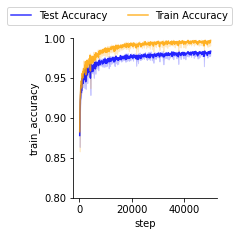

In [63]:
fig = plot_accuracy(df_all, img_path = None, yaxis = (0.8, 1.0), alpha=0.8)

In [66]:
df_10['split'] = "Clustering on training and testing"
df_10_all['split'] = "Clustering only on training"
df_all['split'] = "No clustering"

df_exps = pd.concat((df_10, df_10_all, df_all))
df_exps

,Unnamed: 0,lr,weight_decay,scaling_factor,num_samples,optimization_steps,step,test_accuracy,train_accuracy,train_loss,weight_norm,split
0,0,0.001,0.0001,8,8124,50020,100,0.799254,0.923191,1.365685,127.441094,Clustering on training and testing
1,1,0.001,0.0001,8,8124,50020,200,0.867164,0.973781,0.741024,126.565455,Clustering on training and testing
2,2,0.001,0.0001,8,8124,50020,300,0.850000,0.980305,0.052850,125.926031,Clustering on training and testing
3,3,0.001,0.0001,8,8124,50020,400,0.902239,0.983136,0.316817,125.413169,Clustering on training and testing
4,4,0.001,0.0001,8,8124,50020,500,0.865672,0.986583,0.339305,124.971255,Clustering on training and testing
...,...,...,...,...,...,...,...,...,...,...,...,...
496,496,0.001,0.0001,8,60000,50100,49700,0.985100,0.998467,0.012845,28.631811,No clustering
497,497,0.001,0.0001,8,60000,50100,49800,0.981700,0.995933,0.044043,28.368900,No clustering
498,498,0.001,0.0001,8,60000,50100,49900,0.978000,0.992567,0.031294,28.459679,No clustering
499,499,0.001,0.0001,8,60000,50100,50000,0.981000,0.994750,0.009394,28.661220,No clustering


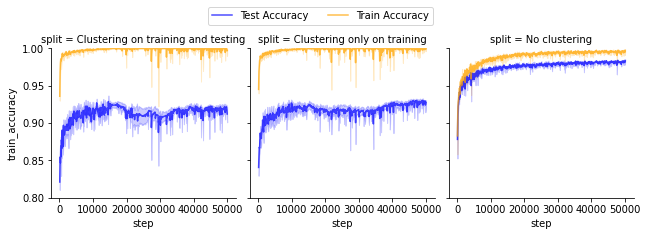

In [67]:
fig = plot_accuracy(df_exps, img_path = None, col = "split", yaxis = (0.8, 1.0), alpha=0.7)